# Weighted Least Squares -- RMST

**This notebook fits weighted least squares regression models to predict RMST pseudo-observations at 1 and 2 years. The model uses gradient boosted survival model predictions at 6 months from first-line treatment for advanced melanoma. Observations are weighted using overlap weights.**

In [1]:
import sys
sys.path.append('../..')

import numpy as np
import pandas as pd
from statsmodels.formula.api import wls
import matplotlib.pyplot as plt

from iptw_survival import OverlapWeightSurvivalEstimator

from utils.treatment_effects import calculate_treatment_effect_curve_rmst
from utils.weighted_quantile import weighted_quantile

## Import data 

### Import calibrated survival probabilities 

In [2]:
surv_pred_df = pd.read_csv('../outputs/gb_6m_survival_predictions_calibrated.csv')

In [3]:
surv_pred_df.head(3)

,PatientID,psurv_180_calibrated
0,F744F618949B5,0.881810
1,F4AAE7EB8AE49,0.586995
2,F702FE1F825B7,0.962108


In [4]:
surv_pred_df.shape

(1069, 2)

### Import treatment assignment

In [5]:
treatment_df = pd.read_csv('../outputs/ioio_tki_index.csv')

In [6]:
treatment_df.shape

(2771, 3)

In [7]:
treatment_df.head(3)

,PatientID,LineName,StartDate
0,F744F618949B5,ioio,2020-04-24
1,F5C59C9946310,ioio,2018-07-17
2,F1A32DD843C2F,ioio,2020-04-15


### Import features

In [8]:
dtype_map = pd.read_csv('../outputs/ioio_tki_features_dtypes.csv', index_col = 0).iloc[:, 0].to_dict()
features_df = pd.read_csv('../outputs/ioio_tki_features_df.csv', dtype = dtype_map)

In [9]:
features_df.shape

(1339, 174)

### Import RMST pseudo-observations

In [10]:
pseudo_obs_df = pd.read_csv('../outputs/pseudo_obs_rmst.csv')

In [11]:
pseudo_obs_df.shape

(1069, 3)

In [12]:
pseudo_obs_df.head(3)

,PatientID,rmst_pseudo_1y,rmst_pseudo_2y
0,F744F618949B5,367.956504,744.340936
1,F4AAE7EB8AE49,357.021846,631.659309
2,F702FE1F825B7,367.956504,744.340936


### Merge dataframes

In [13]:
df = pd.merge(features_df, surv_pred_df, on = 'PatientID', how = 'left')

In [14]:
df.shape

(1339, 175)

In [15]:
df = pd.merge(df, pseudo_obs_df, on = 'PatientID', how = 'left')

In [16]:
df.shape

(1339, 177)

In [17]:
df = pd.merge(df, treatment_df, on = 'PatientID', how = 'left')

In [18]:
df.shape

(1339, 179)

In [19]:
df['StartDate'] = pd.to_datetime(df['StartDate'])

In [20]:
df['treatment_year'] = df['StartDate'].dt.year

In [21]:
df = df.query('treatment_year <= 2021')

In [22]:
df.shape

(1069, 180)

## Calculating overlap weights

In [23]:
df['treatment'] = np.where(df['LineName'] == 'ioio', 1, 0)

In [24]:
df.treatment.value_counts()

treatment
0    652
1    417
Name: count, dtype: int64

In [25]:
estimator = OverlapWeightSurvivalEstimator(normalize = None)

In [26]:
estimator.fit(df = df,
              treatment_col = 'treatment',
              cont_var = ['days_adv_to_treatment', 'age', 'GroupStage_mod', 'ecog_index', 'ses_mod', 'weight_index', 'percent_change_weight', 'albumin', 'total_bilirubin', 'ldh', 'creatinine', 'van_walraven_score'],
              binary_var = ['sex_male', 'medicaid', 'before_2020', 'brain_met', 'liver_met', 'GroupStage_mod_na', 'ecog_index_na', 'ses_mod_na'],
              lr_kwargs = {
                  'class_weight': 'balanced',
                  'solver': 'lbfgs',
                  'penalty': 'l2',
                  'max_iter': 1000,
                  'random_state': 42
              },
              clip_bounds = (0.01, 0.99),
              stabilized = False,
              use_missing_flags = False) 

In [27]:
overlap_df = estimator.transform()

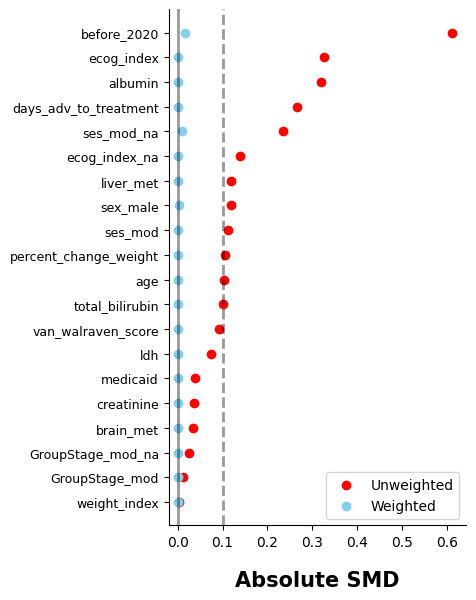

In [28]:
_, smd_fig = estimator.standardized_mean_differences(return_fig = True)

ax = smd_fig.axes[0]

# Resize figure
smd_fig.set_size_inches(4, 6)

# Axis/title font sizes
ax.set_xlabel('Absolute SMD', fontsize=15)
ax.set_title('')

# Reference line styles
for line in ax.lines:
    line.set_alpha(0.4)

ax.tick_params(axis='y', labelsize=9)
ax.legend(prop={'size': 10})
smd_fig.savefig('../outputs/smd_plot_wls.pdf', dpi=300, bbox_inches='tight')
smd_fig

## WLS model

### 1-year RMST

In [29]:
# Create grid of psurv_180 values (5th to 95th percentile)
psurv_grid = np.linspace(
    overlap_df['psurv_180_calibrated'].quantile(0.05),
    overlap_df['psurv_180_calibrated'].quantile(0.95),
    200
)

In [30]:
formula_1y = 'rmst_pseudo_1y ~ treatment * psurv_180_calibrated'

model_1y = wls(
    formula = formula_1y,
    data = overlap_df,
    weights = overlap_df['overlap_weight']
).fit(cov_type='HC3')

print(model_1y.summary())

                            WLS Regression Results                            
Dep. Variable:         rmst_pseudo_1y   R-squared:                       0.176
Model:                            WLS   Adj. R-squared:                  0.174
Method:                 Least Squares   F-statistic:                     62.84
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           2.06e-37
Time:                        22:10:00   Log-Likelihood:                -6546.9
No. Observations:                1069   AIC:                         1.310e+04
Df Residuals:                    1065   BIC:                         1.312e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

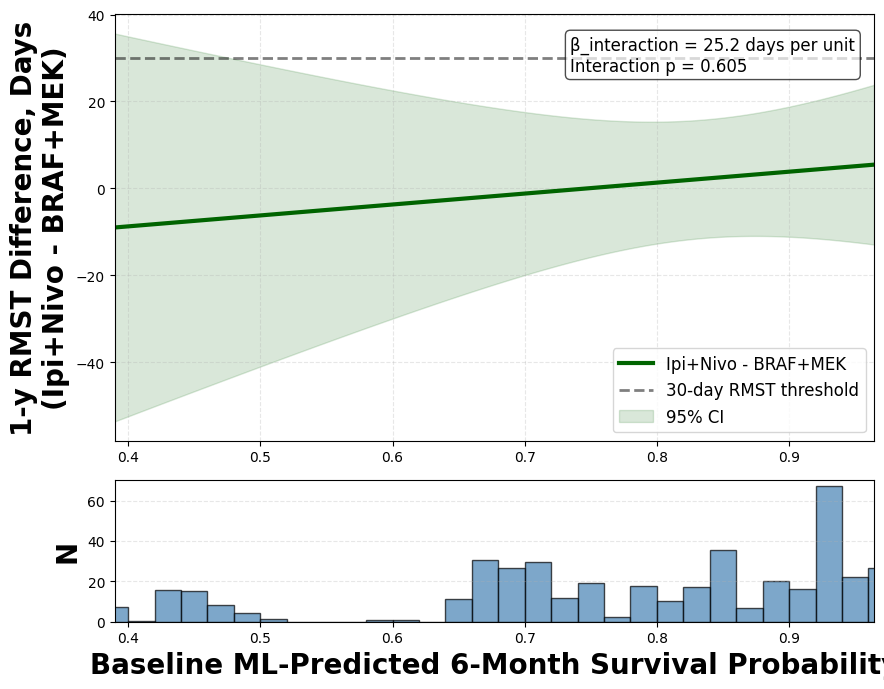

In [31]:
# Calculate treatment effects using the utils function
effect_1y_df = calculate_treatment_effect_curve_rmst(
    model = model_1y,
    baseline_var = 'psurv_180_calibrated',
    baseline_values = psurv_grid
)

# Plot treatment effect
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (9, 7), gridspec_kw = {'height_ratios': [3, 1]})

ax1.plot(effect_1y_df['baseline'], effect_1y_df['treatment_effect'], 
         linewidth = 3, color = 'darkgreen', label = 'Ipi+Nivo - BRAF+MEK')

ax1.axhline(y = 30, color = 'black', linestyle = '--', linewidth = 2, alpha = 0.5, label = '30-day RMST threshold')

# Shade 95% CI
ax1.fill_between(effect_1y_df['baseline'], effect_1y_df['ci_lower'], effect_1y_df['ci_upper'], 
                 alpha = 0.15, color = 'darkgreen', label = '95% CI')

# Extract key stats
interaction_coef = model_1y.params['treatment:psurv_180_calibrated']
interaction_pval = model_1y.pvalues['treatment:psurv_180_calibrated']

# Add text box to plot
stats_text = f'β_interaction = {interaction_coef:.1f} days per unit\n'
stats_text += f'Interaction p = {interaction_pval:.3f}'

ax1.text(0.60, 0.95, stats_text,
         transform = ax1.transAxes,
         fontsize = 12,
         verticalalignment = 'top',
         horizontalalignment = 'left',
         bbox = dict(boxstyle = 'round', facecolor ='white', alpha = 0.7))

ax1.set_ylabel('1-y RMST Difference, Days\n(Ipi+Nivo - BRAF+MEK)', fontsize = 20, fontweight = 'bold')
ax1.legend(fontsize =12, loc = 'lower right')
ax1.grid(alpha = 0.3, linestyle = '--')
ax1.set_xlim([psurv_grid.min(), psurv_grid.max()])

# Bottom panel
ax2.hist(overlap_df['psurv_180_calibrated'], 
         bins = 50,
         weights = overlap_df['overlap_weight'],
         alpha = 0.7, 
         edgecolor = 'black', 
         color = 'steelblue')

ax2.set_xlabel('Baseline ML-Predicted 6-Month Survival Probability', fontsize = 20, fontweight = 'bold')
ax2.set_ylabel('N', fontsize = 20, fontweight = 'bold')
ax2.set_xlim([psurv_grid.min(), psurv_grid.max()])
ax2.grid(alpha = 0.3, linestyle = '--', axis = 'y')

plt.tight_layout()
plt.show()

In [32]:
def treatment_effect_at_r(model, r):
    contrast = pd.Series(0.0, index=model.params.index)

    contrast["treatment"] = 1.0
    contrast["treatment:psurv_180_calibrated"] = r

    result = model.t_test(contrast.to_numpy())

    estimate = float(np.asarray(result.effect).squeeze())
    ci_lower, ci_upper = np.asarray(result.conf_int()).squeeze()

    return estimate, ci_lower, ci_upper

# Weighted 10th and 90th percentiles of predicted survival
r10, r90 = weighted_quantile(
    overlap_df["psurv_180_calibrated"],
    quantiles=[0.10, 0.90],
    sample_weight=overlap_df["overlap_weight"]
)


In [33]:
# Treatment effects at the 10th and 90th percentiles
te10, te10_low, te10_high = treatment_effect_at_r(model_1y, r10)
te90, te90_low, te90_high = treatment_effect_at_r(model_1y, r90)

# Difference in treatment effect between the 10th and 90th percentiles
contrast = pd.Series(0.0, index=model_1y.params.index)
contrast["treatment:psurv_180_calibrated"] = r10 - r90

result = model_1y.t_test(contrast.to_numpy())

te_diff = float(np.asarray(result.effect).squeeze())
te_diff_low, te_diff_high = np.asarray(result.conf_int()).squeeze()

# Display results
print(
    f"TE at 10th percentile (r={r10:.3f}): "
    f"{te10:.1f} days "
    f"(95% CI, {te10_low:.1f} to {te10_high:.1f})"
)

print(
    f"TE at 90th percentile (r={r90:.3f}): "
    f"{te90:.1f} days "
    f"(95% CI, {te90_low:.1f} to {te90_high:.1f})"
)

print(
    f"10th–90th percentile ΔTE: "
    f"{te_diff:.1f} days "
    f"(95% CI, {te_diff_low:.1f} to {te_diff_high:.1f})"
)

TE at 10th percentile (r=0.445): -7.6 days (95% CI, -47.3 to 32.1)
TE at 90th percentile (r=0.949): 5.1 days (95% CI, -12.4 to 22.5)
10th–90th percentile ΔTE: -12.7 days (95% CI, -60.9 to 35.5)


In [34]:
### 2-year RMST

In [35]:
formula_2y = 'rmst_pseudo_2y ~ treatment * psurv_180_calibrated'

model_2y = wls(
    formula = formula_2y,
    data = overlap_df,
    weights = overlap_df['overlap_weight']
).fit(cov_type='HC3')

print(model_2y.summary())

                            WLS Regression Results                            
Dep. Variable:         rmst_pseudo_2y   R-squared:                       0.183
Model:                            WLS   Adj. R-squared:                  0.181
Method:                 Least Squares   F-statistic:                     81.85
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           1.19e-47
Time:                        22:10:00   Log-Likelihood:                -7470.8
No. Observations:                1069   AIC:                         1.495e+04
Df Residuals:                    1065   BIC:                         1.497e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

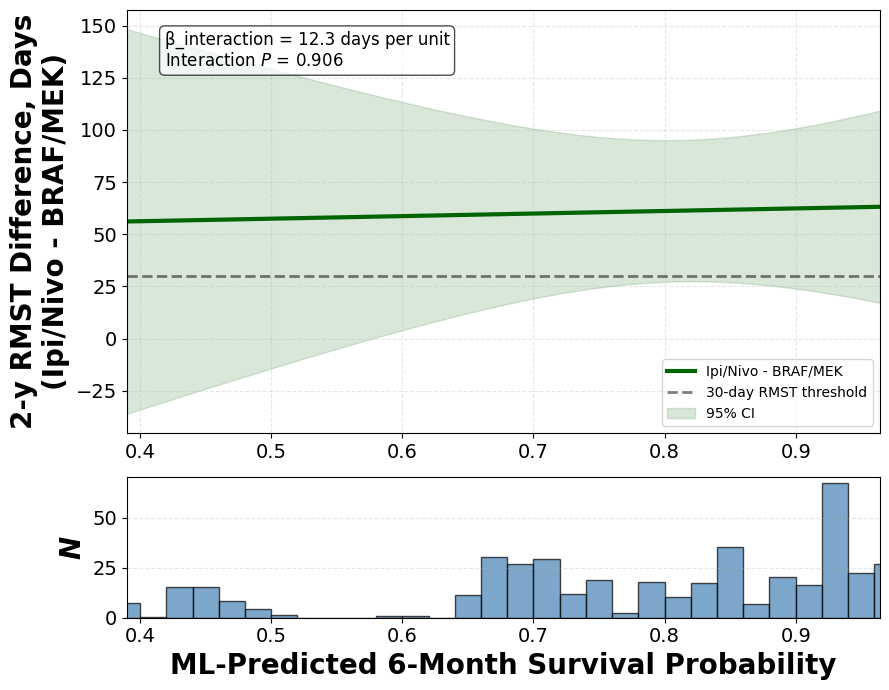

In [36]:
# Calculate treatment effects using the utils function
effect_2y_df = calculate_treatment_effect_curve_rmst(
    model = model_2y,
    baseline_var = 'psurv_180_calibrated',
    baseline_values = psurv_grid
)

# Plot treatment effect
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (9, 7), gridspec_kw = {'height_ratios': [3, 1]})

ax1.plot(effect_2y_df['baseline'], effect_2y_df['treatment_effect'], 
         linewidth = 3, color = 'darkgreen', label = 'Ipi/Nivo - BRAF/MEK')

ax1.axhline(y = 30, color = 'black', linestyle = '--', linewidth = 2, alpha = 0.5, label = '30-day RMST threshold')

# Shade 95% CI
ax1.fill_between(effect_2y_df['baseline'], effect_2y_df['ci_lower'], effect_2y_df['ci_upper'], 
                 alpha = 0.15, color = 'darkgreen', label = '95% CI')

# Define crossover value 
crossover_value = 30  

# Calculate crossover point algebraically: TE(r) = beta1 + beta3*r = crossover_value
# Solving for r: r = (crossover_value - beta1) / beta3
beta1 = model_2y.params['treatment']
beta3 = model_2y.params['treatment:psurv_180_calibrated']
crossover_survival_estimate = (crossover_value - beta1) / beta3

# Check if crossover point is within the observed data range
crossover_in_range = (crossover_survival_estimate >= psurv_grid.min()) and (crossover_survival_estimate <= psurv_grid.max())

# Add vertical line at crossover point if it's in range
if crossover_in_range:
    ax1.axvline(x = crossover_survival_estimate, color = 'purple', alpha = 0.8, linestyle = '-.', linewidth = 2, 
               label = f'Crossover point (r = {crossover_survival_estimate:.2f})')

ax1.set_ylabel('2-y RMST Difference, Days\n(Ipi/Nivo - BRAF/MEK)', fontsize = 20, fontweight = 'bold')

ax1.legend(fontsize = 10, loc = 'lower right')
ax1.grid(alpha = 0.3, linestyle = '--')
ax1.set_xlim([psurv_grid.min(), psurv_grid.max()])
ax1.tick_params(axis='both', labelsize=14)

# Extract key stats
interaction_coef = model_2y.params['treatment:psurv_180_calibrated']
interaction_pval = model_2y.pvalues['treatment:psurv_180_calibrated']

# Format p-value for display
if interaction_pval < 0.001:
    pval_text = '<0.001'
else:
    pval_text = f'{interaction_pval:.3f}'

# Add text box to plot
stats_text = f'β_interaction = {interaction_coef:.1f} days per unit\n'
stats_text += f'Interaction $P$ = {pval_text}'

ax1.text(0.05, 0.95, stats_text,
         transform = ax1.transAxes,
         fontsize = 12,
         verticalalignment = 'top',
         horizontalalignment = 'left',
         bbox = dict(boxstyle = 'round', facecolor ='white', alpha = 0.7))

# Bottom panel
ax2.hist(overlap_df['psurv_180_calibrated'], 
         bins = 50,
         weights = overlap_df['overlap_weight'],
         alpha = 0.7, 
         edgecolor = 'black', 
         color = 'steelblue')

# Add crossover line to bottom panel if in range
if crossover_in_range:
    ax2.axvline(x = crossover_survival_estimate, color = 'purple', alpha = 0.8, linestyle = '-.', linewidth = 2)
    
    # Calculate weighted percentile below crossover
    weighted_pct_below = (
        overlap_df.loc[overlap_df['psurv_180_calibrated'] <= crossover_survival_estimate, 'overlap_weight'].sum() / 
        overlap_df['overlap_weight'].sum() * 100
    )
    
    # Add percentile annotation
    ax2.text(crossover_survival_estimate - 0.13, ax2.get_ylim()[1]*0.65, 
             f"{weighted_pct_below:.1f}%", 
             ha = 'left', fontsize = 12,
             bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.7))

ax2.set_xlabel('ML-Predicted 6-Month Survival Probability', fontsize = 20, fontweight = 'bold')
ax2.set_ylabel('N', fontsize = 20, fontweight='bold', fontstyle='italic')
ax2.set_xlim([psurv_grid.min(), psurv_grid.max()])
ax2.grid(alpha = 0.3, linestyle = '--', axis = 'y')
ax2.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.savefig('../outputs/wls_rmst_2y.pdf', format = 'pdf', bbox_inches = 'tight')
plt.show()

In [37]:
# Define additional crossover values for sensitivity analysis 
crossover_value_14 = 14
crossover_value_60 = 60

# Calculate crossover point algebraically: TE(r) = beta1 + beta3*r = crossover_value
# Solving for r: r = (crossover_value - beta1) / beta3
beta1 = model_2y.params['treatment']
beta3 = model_2y.params['treatment:psurv_180_calibrated']
crossover_survival_estimate_14 = (crossover_value_14 - beta1) / beta3
crossover_survival_estimate_60 = (crossover_value_60 - beta1) / beta3

# Save 14d crossover survival estimate
with open('../outputs/crossover_survival_estimate_14.txt', 'w') as f:
    f.write(str(crossover_survival_estimate_14))

# Save 30d crossover survival estimate
with open('../outputs/crossover_survival_estimate.txt', 'w') as f:
    f.write(str(crossover_survival_estimate))

# Save 60d crossover survival estimate
with open('../outputs/crossover_survival_estimate_60.txt', 'w') as f:
    f.write(str(crossover_survival_estimate_60))

In [38]:
# Treatment effects at the 10th and 90th percentiles
te10, te10_low, te10_high = treatment_effect_at_r(model_2y, r10)
te90, te90_low, te90_high = treatment_effect_at_r(model_2y, r90)

# Difference in treatment effect between the 10th and 90th percentiles
contrast = pd.Series(0.0, index=model_2y.params.index)
contrast["treatment:psurv_180_calibrated"] = r10 - r90

result = model_2y.t_test(contrast.to_numpy())

te_diff = float(np.asarray(result.effect).squeeze())
te_diff_low, te_diff_high = np.asarray(result.conf_int()).squeeze()

# Display results
print(
    f"TE at 10th percentile (r={r10:.3f}): "
    f"{te10:.1f} days "
    f"(95% CI, {te10_low:.1f} to {te10_high:.1f})"
)

print(
    f"TE at 90th percentile (r={r90:.3f}): "
    f"{te90:.1f} days "
    f"(95% CI, {te90_low:.1f} to {te90_high:.1f})"
)

print(
    f"10th–90th percentile ΔTE: "
    f"{te_diff:.1f} days "
    f"(95% CI, {te_diff_low:.1f} to {te_diff_high:.1f})"
)

TE at 10th percentile (r=0.445): 56.8 days (95% CI, -25.1 to 138.7)
TE at 90th percentile (r=0.949): 63.0 days (95% CI, 19.0 to 107.0)
10th–90th percentile ΔTE: -6.2 days (95% CI, -108.8 to 96.5)
